# EKF G/F and S · variable CO₂ solubility
New standalone copy; the previous filter notebooks remain unchanged. Six fermentations, CO₂-only causal replay: RAW means over completed 30-minute windows, model gas integrated over the same windows, causal temperature from completed one-minute bins. Chemical measurements are used only for evaluation. Initial ethanol remains the previous 10.010194 g/L assumption (sigma 2 g/L); no initial holdout ethanol is assimilated. Signal screening, nutrient pulses, activation and initial-state policy are unchanged; no new spike treatment is introduced.

## Gas model and fixed calibration
\[
a=E/7.8924,\quad S=G+F\text{ or the single-sugar state},\quad
C_{sat}=3.295\exp[(7\cdot10^{-5}a-0.02905)T-0.0179a-0.00111S]p_{CO_2}.
\]
T in °C, a in % vol, E and S in g/L. pCO2=1 bar is an explicit assumption. The empirical wine correlation is reproduced as Eq. 1 in [Liger-Belair et al. (2023)](https://doi.org/10.1021/acsomega.3c01812), attributed there to Lonvaud-Funel and Matsumoto. Its applicability to fermenting must, particularly high sugar, is not independently validated here. Ethanol conversion uses pure ethanol density 789.24 g/L at 20°C as a reference conversion.
\[
q_{eff}=Aq_{prod},\quad r_{abs}=\min(q_{eff},k_La\max(C_{sat}-C_d,0)),\quad
r_{des}=k_La\max(C_d-C_{sat},0),\quad
\dot C_d=r_{abs}-r_{des},\quad \dot I=g(q_{eff}-\dot C_d).
\]
This transfer law is our adaptation; it is not attributed to the solubility paper. Csat is recomputed from each current state and causal temperature at every RK4 stage and for every UKF sigma point. Cd may exceed saturation; there is no upper clipping to Csat or 1.5 g/L. Nonnegativity projection and its approximate covariance treatment are retained.

| Chemical model | kLa [h⁻¹] | Gain |
|---|---:|---:|
| G/F | 0.15007991020720535 | 0.6460643588058115 |
| S | 0.13796553316180868 | 0.6586783889606775 |

These are frozen gas fits from the new variable-solubility notebooks (LAB019–021 training, LAB016–018 holdout, hourly RAW medians). No fit is performed inside these filters. LAB019–021 are therefore not blind gas holdout. The filter observation operator remains the causal 30-minute mean.

## Covariances and numerical policy
Original P0 is retained: sigmaX=max(0.03,0.2X0), sigmaN=0.015, sigmaE=2 g/L, sigma(G+F)=5 g/L. G/F has the original correlated allocation (varG=12.5, varF=37.5, cov=-12.5; original ratio propagation for LAB016–018); S has variance 25. Cd and gas-integral initial variances are zero. R=0.04² in (g/(L h))². Q uses the original four flux intensities (0.003,0.08,0.08,0.01) per square-root hour; its state-dependent absorption/emission mapping now uses variable Csat. No independent transfer, temperature or pressure uncertainty is added. These remain exploratory noise assumptions.

EKF transition Jacobians use finite differences of the complete new model, including the ethanol/sugar effect on solubility. Observation H selects I/0.5; correction uses Joseph form. RK4 step is 1 minute, covariance propagation grid 5 minutes, with unchanged nutrient events and accumulator resets. Local derivatives at piecewise branch changes remain approximations. UKF, where present, retains alpha=1, beta=2, kappa=0, 2n+1 points (15 G/F, 13 S), projected only to nonnegative states, with the original covariance/projection audit. No matrices are tuned using offline errors.


Nutrition-associated analytical samples are included in the YAN RMSE and displayed as Samples. They remain evaluation data; the filter assimilation policy is unchanged.


In [1]:
from IPython.utils.capture import capture_output
# Definiciones congeladas y preparación de datos, visibles para auditoría.
with capture_output():
 from pathlib import Path
 from dataclasses import replace
 import sys,json,hashlib,math,time
 import numpy as np,pandas as pd
 import matplotlib.pyplot as plt
 from scipy.integrate import solve_ivp
 from scipy.optimize import least_squares,minimize_scalar
 from IPython.display import display
 ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
 assert Path(sys.prefix).name.lower()=='fermentation'
 sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
 from wine_fermentation import model as kin
 from wine_fermentation.data import natural_batches
 from wine_fermentation.models.historical.calibration import load
 from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
 NAME='06_zenteno_single_sugar_variable_solubility'
 protected=[p for folder in ['src','configs','data/compatibility/chemistry','data/cleaned/natural/lab004_009','notebooks'] for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and not p.name.startswith(('05_zenteno_co2_variable_solubility.','06_zenteno_single_sugar_variable_solubility.','07_ukf_ekf_variable_solubility.'))]
 hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
 data,training,profiles=natural_batches(ROOT)
 # Correcciones de recuento inicial indicadas por el usuario; originales conservados.
 INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
 initial_biomass_audit=[];corrected_training=[]
 for batch in training:
  if batch.batch in INITIAL_VIABLE_MCELLS_ML:
   count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
   ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
   obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
   initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
   batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
   mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
   assert mask.sum()==1
   data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
   assert batch.initials['X']==batch.observations['X'][ids[0]]
  corrected_training.append(batch)
 training=corrected_training
 assert len(initial_biomass_audit)==2
 display(pd.DataFrame(initial_biomass_audit))
 
 start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
 config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
 # Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
 KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
 KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
 start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
 KD0_ZENTENO_H=0.00044
 start['Kd0']=KD0_ZENTENO_H
 assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
 display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
 names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
 assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
 bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
 fixed={k:v for k,v in start.items() if k not in names}
 display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
 display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))
 
 diffs=[]
 bylab={b.batch:b for b in training}
 for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
  aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
  z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
 sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
 assert len(diffs)>0
 print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX aplicada:',SIGMA_X)
 treated=[];audit=[];rules=[]
 for b in training:
  obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
  obs['N'][np.isfinite(old)&(old<=.020)]=0
  if b.batch=='LAB006':
   ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
   obs['N'][ids]=0;depletion=122.
  else:
   last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
   depletion=float(b.time[ids[0]])
  obs['N'][b.time>depletion+12]=np.nan
  for i in np.flatnonzero(np.isfinite(old)):
   audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
  assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
  treated.append(replace(b,observations=obs))
  rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
 audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
 def sigma(state,y):return np.full_like(y,SIGMA_X) if state=='X' else kin.sigma_for_state(state,y)
 def simulate(b,p):
  def rhs(t,y):
   out=np.asarray(kin.rhs(t,y,p,b))
   if y[2]<=0 or y[3]<=0:
    q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
    out[0]-=growth;out[1]+=growth/p['Yxn'];out[2]+=growth/p['Yxg'];out[3]+=growth/p['Yxf']
   return out
  # Muestra previa al salto si coincide con la nutrición; dosis completa después.
  minimum=np.full(5,np.inf);jumps=[];events={}
  for tp,dose in b.pulses.get('N',()):
   assert tp>float(b.time[0]) and dose>=0,'No se admiten pulsos iniciales extra'
   if tp<=b.time[-1]:events[float(tp)]=events.get(float(tp),0.)+float(dose)
  times=np.asarray(b.time);state=kin.initial_vector(b);records={float(times[0]):state.copy()};now=float(times[0])
  for end in sorted(set([float(times[-1])]+list(events))):
   requested=times[(times>now)&(times<=end)]
   sol=solve_ivp(rhs,(now,end),state,t_eval=np.unique(np.r_[requested,end]),method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
   if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-4,1e-6])):raise RuntimeError('Integración química inválida '+b.batch+' '+str(sol.message)+' mínimos='+str(dict(zip(kin.STATE_NAMES,sol.y.min(axis=1)))))
   minimum=np.minimum(minimum,sol.y.min(axis=1))
   records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)});state=sol.y[:,-1].copy();now=end
   if end in events:
    before=state.copy();state[1]+=events[end]
    assert np.isclose(state[1]-before[1],events[end],atol=1e-12) and np.array_equal(state[[0,2,3,4]],before[[0,2,3,4]])
    jumps.append(dict(t=end,dose=events[end],before=before.copy(),after=state.copy()))
  f=pd.DataFrame(np.maximum(np.vstack([records[float(t)] for t in times]),0),index=times,columns=kin.STATE_NAMES);f['GF']=f.G+f.F
  f.attrs['minimum_integrated_states']=dict(zip(kin.STATE_NAMES,minimum.tolist()))
  f.attrs['pulse_jumps']=jumps
  assert np.isclose(sum(j['dose'] for j in jumps),sum(events.values()),atol=1e-12)
  return f
 
 def with_jumps(f):
  extra=[];tt=[]
  for j in f.attrs['pulse_jumps']:
   if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
   extra.append(j['after']);tt.append(j['t'])
  if not extra:return f
  added=pd.DataFrame(extra,index=tt,columns=kin.STATE_NAMES);added['GF']=added.G+added.F
  return pd.concat([f,added]).sort_index(kind='stable')
 
 support=[(b,s,np.isfinite(b.observations[s])&(b.time>0)) for b in treated for s in kin.STATE_NAMES]
 NR=sum(m.sum() for b,s,m in support);calls=0;rejected=0
 
 # Química congelada de la recalibración anterior; sin optimización en esta prueba.
 theta={'mu0': 0.09403147367985473, 'betaG0': 0.42243676903335664, 'betaF0': 0.6236552480900203, 'Kn0': 0.008257860224319971, 'Kg0': 4.400775419123265, 'Kf0': 19.296083508118652, 'Kig0': 65.01993873457147, 'Kie0': 96.26516563486751, 'Kd0': 0.00044, 'Yxn': 6.456225797038313, 'Yxg': 0.9660935553477866, 'Yxf': 1.1098958529485594, 'Yeg': 0.4684585383875136, 'Yef': 0.5113278649826252, 'm0': 0.0183385793928771}
 assert theta['Kn0']==start['Kn0'] and theta['Kd0']==KD0_ZENTENO_H
 assert all(theta[k]==v for k,v in fixed.items())
 print('PARÁMETROS QUÍMICOS COMPLETOS',json.dumps(theta,indent=2))
 print('Química fija: no se recalibra en esta prueba de activación.')
 traincurves={b.batch:simulate(b,theta) for b in treated}
 
 v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
 raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
 batches={};cores={};volumes={};caches={};activation={};entry=[]
 for lab in LABS:
  b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
  def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
  volumes[lab]=volume
  if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
  if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
  if lab=='LAB021':b=replace(b,initials={**b.initials,'X':9.*.03})
  batches[lab]=b;f=simulate(b,theta);cores[lab]=f;f=with_jumps(f)
  tt=np.unique(np.r_[np.arange(0,float(f.index[-1]),.1),f.index[-1]])
  rates=[]
  for t in tt:
   y=[np.interp(t,f.index,f[s]) for s in kin.STATE_NAMES];q=kin.kinetic_terms(theta,kin.temperature_at(b,t),*y)
   if y[2]<=0 or y[3]<=0:q['mu']=0.
   rates.append((q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*y[0])
  caches[lab]=(tt,np.asarray(rates))
  consumed=b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.GF)
  z=np.clip((consumed-5.)/5.,0.,1.);activation[lab]=z*z*(3.-2.*z)
  assert np.all(activation[lab][consumed<=5.]==0) and np.all(activation[lab][consumed>=10.]==1)
  entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
  obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
 display(pd.DataFrame(entry))

GAS_PARAMETERS={'GF':(.15007991020720535,.6460643588058115),
                'S':(.13796553316180868,.6586783889606775)}
PCO2_BAR=1.
def co2_saturation(T,E,S):
 a=np.maximum(E,0.)/7.8924
 return 3.295*np.exp((7e-5*a-.02905)*T-.0179*a-.00111*np.maximum(S,0.))*PCO2_BAR

def gas_exchange(qp,cd,T,E,S):
 cs=co2_saturation(T,E,S)
 absorption=np.minimum(qp,KLA*np.maximum(cs-cd,0.))
 desorption=KLA*np.maximum(cd-cs,0.)
 accumulation=absorption-desorption
 return accumulation,qp-accumulation

def validate_variable_gas(single=False):
 # Check thermal/composition effects, conservation, supersaturation and Jacobian.
 assert co2_saturation(25.,0.,0.)<co2_saturation(20.,0.,0.)
 assert co2_saturation(20.,80.,0.)<co2_saturation(20.,0.,0.)
 assert co2_saturation(20.,0.,200.)<co2_saturation(20.,0.,0.)
 cs=float(co2_saturation(20.,30.,90.))
 uptake,emission=gas_exchange(0.,cs+.5,20.,30.,90.)
 assert uptake<0 and emission>0 and abs(uptake+emission)<1e-12
 test=np.array([1.,.05,90.,30.,cs+.5,0.]) if single else np.array([1.,.05,40.,50.,30.,cs+.5,0.])
 rates=rates_ekf(test[None,:],24.,20.,160.)[0]
 if single:
  x,n,s,e,cd=test[:5];tk=293.15;R=8.314
  ak=np.exp(46055*(tk-293.15)/(293.15*R*tk));mu=PS['mu0']*np.exp(59453*(tk-300)/(300*R*tk))*n/(n+theta['Kn0']*ak+1e-8)
  beta=PS['betaS0']*np.exp(11000*(tk-296.15)/(296.15*R*tk))*s/(s+PS['Ks0']*ak+1e-8)/(1+e/(PS['Kie0']*(ak+1e-8)))
  source=(mu/12.72+beta/1.05)*x
 else:
  q=kin.kinetic_terms(theta,20.,*test[:5]);source=(q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*test[0]
 # S0-S=70g/L: activation is exactly one.
 assert abs(rates[-2]+rates[-1]/GAIN-source)<1e-8
 assert rates[-2]<0
 z=test/SCALE_EKF;end=24.+1/12
 x,J=jacobian(z,24.,end,lambda t:20.,160.)
 eps=2e-6;numeric=[]
 for j in range(len(z)):
  delta=np.eye(len(z))[j]*eps
  numeric.append((transition(z+delta,24.,end,lambda t:20.,160.)[0]-transition(z,24.,end,lambda t:20.,160.)[0])/eps)
 assert np.max(abs(J-np.array(numeric).T))<2e-3
 fine=transition(z,24.,end,lambda t:20.,160.,step=1/120)[0]
 assert np.max(abs((x-fine)*SCALE_EKF))<1e-4
 Q=noise_matrix(test,20.,160.)
 assert np.linalg.eigvalsh(Q).min()>-1e-10
 print('Variable gas: composition/temperature, balance, desorption, transition Jacobian, PSD Q and time-step refinement verified.')

KLA,GAIN=GAS_PARAMETERS['GF']
SCALE_EKF=np.array([.3,.25,80.,80.,15.,.2,1.])
BASE_THETA=theta.copy();BASE_GAS=(KLA,GAIN)
print('Química fija:',json.dumps(theta,indent=2));print('kLa, ganancia:',KLA,GAIN)


Química fija: {
  "mu0": 0.09403147367985473,
  "betaG0": 0.42243676903335664,
  "betaF0": 0.6236552480900203,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 65.01993873457147,
  "Kie0": 96.26516563486751,
  "Kd0": 0.00044,
  "Yxn": 6.456225797038313,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.4684585383875136,
  "Yef": 0.5113278649826252,
  "m0": 0.0183385793928771
}
kLa, ganancia: 0.15007991020720535 0.6460643588058115


## EKF G/F · variable solubility

In [2]:

def rates_ekf(w,t,T,S0):
 x,n,g,f,e,cd=np.maximum(w[:,:6],0.).T;tk=T+273.15;R=8.314
 am=np.exp(59453*(tk-300)/(300*R*tk));ab=np.exp(11000*(tk-296.15)/(296.15*R*tk));ak=np.exp(46055*(tk-293.15)/(293.15*R*tk))
 mu=theta['mu0']*am*n/(n+theta['Kn0']*ak+1e-8);mu=np.where((g<=0)|(f<=0),0.,mu)
 bg=theta['betaG0']*ab*g/(g+theta['Kg0']*ak+1e-8)/(1+e/(theta['Kie0']*(ak+1e-8)))
 bf=theta['betaF0']*ab*f/(f+theta['Kf0']*ak+1e-8)/(1+g/(theta['Kig0']*(ak+1e-8)))/(1+e/(theta['Kie0']*(ak+1e-8)))
 td=-.0001*e**3+.0049*e**2-.1279*e+315.89
 kd=np.where(tk>=td,theta['Kd0']*np.exp(.0415*e+130000*(tk-305.65)/(305.65*R*tk)),0.)
 m=theta['m0']*np.exp(37681*(tk-293.3)/(293.3*R*tk))*(g+f+1e-8)/(g+f+1+1e-8)
 z=np.clip((S0-g-f-5)/5,0,1);A=z*z*(3-2*z)
 qp=A*(mu/12.72+(bg+bf)/1.05)*x
 acc,gas=gas_exchange(qp,cd,T,e,g+f)
 return np.column_stack([(mu-kd)*x,-mu*x/theta['Yxn'],-(mu/theta['Yxg']+bg/theta['Yeg']+m*g/(g+f+1e-8))*x,-(mu/theta['Yxf']+bf/theta['Yef']+m*f/(g+f+1e-8))*x,(bg+bf)*x,acc,GAIN*gas])

def transition(z,start,end,Tfun,S0,step=1/60):
 w=np.atleast_2d(z)*SCALE_EKF;n=max(1,int(np.ceil((end-start)/step-1e-7)));dt=(end-start)/n
 for j in range(n):
  t=start+j*dt
  k1=rates_ekf(w,t,Tfun(t),S0);k2=rates_ekf(w+dt*k1/2,t+dt/2,Tfun(t+dt/2),S0)
  k3=rates_ekf(w+dt*k2/2,t+dt/2,Tfun(t+dt/2),S0);k4=rates_ekf(w+dt*k3,t+dt,Tfun(t+dt),S0)
  w+=dt*(k1+2*k2+2*k3+k4)/6
  w=np.maximum(w,0)
 return w/SCALE_EKF

def jacobian(z,start,end,Tfun,S0):
 eps=1e-5;delta=np.eye(7)*eps;lower=z-delta
 den=np.where(z>=eps,2*eps,eps)
 for j in range(7):
  if z[j]<eps:lower[j]=z
 out=transition(np.vstack([z,z+delta,lower]),start,end,Tfun,S0)
 J=((out[1:8]-out[8:])/den[:,None]).T
 return out[0],J

def noise_matrix(state,T,S0):
 # Flux mapping through the active accumulation/emission branch.
 x,n,g,f,e,cd=state[:6];z=np.clip((S0-g-f-5)/5,0,1);A=z*z*(3-2*z)
 qp=float(rates_ekf(np.array([state]),0,T,S0)[0,5]+rates_ekf(np.array([state]),0,T,S0)[0,6]/GAIN)
 dissolved=float(qp<KLA*max(float(co2_saturation(T,e,g+f))-cd,0))
 L=np.zeros((7,4));L[:5,0]=[1,-1/theta['Yxn'],-1/theta['Yxg'],-1/theta['Yxf'],0]
 L[2,1]=-1;L[4,1]=theta['Yeg'];L[3,2]=-1;L[4,2]=theta['Yef']
 production=A*np.array([1/12.72,theta['Yeg']/1.05,theta['Yef']/1.05,1])
 L[5]=dissolved*production;L[6]=GAIN*(1-dissolved)*production
 return (L@np.diag(np.array([.003,.08,.08,.01])**2)@L.T)/np.outer(SCALE_EKF,SCALE_EKF)

validate_variable_gas(single=False)
R_CO2=.04**2
RESULTS={};initial_audit=[];sensor_audit=[]
for lab in LABS:
 batch=batches[lab];horizon=float(v.horizons[lab]);rawt=v.raw_temperature[lab].copy();rawt['minute']=np.floor(rawt.t_h*60).astype(int)
 temp=rawt.groupby('minute')['T'].median().dropna();available=(temp.index.to_numpy()+1)/60;values=temp.to_numpy(float)
 def Tfun(t,available=available,values=values):
  j=np.searchsorted(available,t+1e-12,side='right')-1
  assert j>=0 and available[j]<=t+1e-10
  return float(values[j])
 rawg=v.raw_co2[lab].copy();rawg['bin']=np.ceil(rawg.t_h/.5-1e-10).astype(int)
 rows=[]
 for end in np.arange(.5,horizon+1e-9,.5):
  g0=rawg.loc[rawg.bin.eq(round(end/.5))].dropna(subset=['flow_sccm']);gaps=np.diff(np.r_[end-.5,g0.t_h.to_numpy(),end])
  factor=44.0095*60*.74/(1000*24.16)
  yy=g0.flow_sccm.to_numpy()*factor/volumes[lab](g0.t_h.to_numpy())
  valid=len(g0)>=30 and gaps.max()<=2/60
  rows.append(dict(t_h=end,y=float(np.mean(yy)) if len(yy) else np.nan,valid=valid))
 sensor=pd.DataFrame(rows);sensor['assimilate']=sensor.valid&sensor.y.ge(.05)&sensor.valid.shift(fill_value=False)&sensor.y.shift().ge(.05)
 sensor_audit.append(dict(LAB=lab,ventanas=len(sensor),asimiladas=int(sensor.assimilate.sum())))
 initial=np.array([batch.initials[k] for k in kin.STATE_NAMES]+[0.]);initial[4]=10.010194;S0=initial[2]+initial[3]
 P=np.diag([max(.03,.2*initial[0])**2,.015**2,12.5,37.5,4,0.,0.]);P[2,3]=P[3,2]=-12.5
 if lab in HOLD:
  r=initial[2]/S0;P[2,2]=r*r*25+25;P[3,3]=(1-r)**2*25+25;P[2,3]=P[3,2]=r*(1-r)*25-25
 initial_audit.append(dict(LAB=lab,**dict(zip(kin.STATE_NAMES,initial[:5])),sigma_X=np.sqrt(P[0,0]),sigma_GF=np.sqrt(P[2,2]+P[3,3]+2*P[2,3])))
 z=np.r_[initial,0.]/SCALE_EKF;free=z.copy();P=P/np.outer(SCALE_EKF,SCALE_EKF)
 timegrid=np.unique(np.round(np.r_[np.arange(0,horizon,1/12),sensor.t_h,horizon,[t for t,d in batch.pulses['N']]],10))
 events={round(t,10):d for t,d in batch.pulses['N']};records=[];forecasts=[];diag=[];snap=[]
 for i,t in enumerate(timegrid):
  if i:
   start=timegrid[i-1];dt=t-start;before=z.copy();z,J=jacobian(z,start,t,Tfun,S0)
   W=noise_matrix(before*SCALE_EKF,Tfun(start),S0)*dt
   P=J@P@J.T+W;P=(P+P.T)/2
   free=transition(free,start,t,Tfun,S0)[0]
  if t in events:z[1]+=events[t]/SCALE_EKF[1];free[1]+=events[t]/SCALE_EKF[1]
  if t>0 and abs(t/.5-round(t/.5))<1e-8:
   o=sensor.iloc[round(t/.5)-1];prediction=z[6]/.5;predfree=free[6]/.5
   forecasts.append(dict(t_h=t,measured=o.y,forecast=prediction,free=predfree,valid=o.valid,assimilate=o.assimilate))
   if o.assimilate:
    H=np.zeros(7);H[6]=2.;S=float(H@P@H+R_CO2);K=P@H/S;innovation=o.y-prediction
    updated=z+K*innovation;clipped=int(np.sum(updated[:6]<0))
    B=np.eye(7)-np.outer(K,H);P=B@P@B.T+np.outer(K,K)*R_CO2;P=(P+P.T)/2
    z=np.maximum(updated,0)
    diag.append(dict(t_h=t,innovation=innovation,NIS=innovation**2/S,recortes=clipped))
   z[6]=0.;free[6]=0.;P[6,:]=0.;P[:,6]=0.
  assert np.isfinite(z).all() and np.linalg.eigvalsh(P).min()>-1e-7
  records.append(np.r_[t,z[:6]*SCALE_EKF[:6],free[:6]*SCALE_EKF[:6]]);snap.append(np.diag(P)[:6]*SCALE_EKF[:6]**2)
 frame=pd.DataFrame(records,columns=['t_h']+['EKF_'+k for k in ['X','N','G','F','E','Cd']]+['Libre_'+k for k in ['X','N','G','F','E','Cd']])
 for prefix in ['EKF_','Libre_']:frame[prefix+'GF']=frame[prefix+'G']+frame[prefix+'F']
 RESULTS[lab]=dict(frame=frame,sensor=pd.DataFrame(forecasts),diag=pd.DataFrame(diag),variance=np.array(snap))
 print(lab,'terminado, correcciones',len(diag),'recortes',sum(d['recortes'] for d in diag),flush=True)
display(pd.DataFrame(initial_audit));display(pd.DataFrame(sensor_audit))

RESULTS_GF=RESULTS;SCALE_GF=SCALE_EKF.copy();THETA_GF=theta.copy()


Variable gas: composition/temperature, balance, desorption, transition Jacobian, PSD Q and time-step refinement verified.
LAB019 terminado, correcciones 217 recortes 62
LAB020 terminado, correcciones 223 recortes 16
LAB021 terminado, correcciones 166 recortes 23
LAB016 terminado, correcciones 249 recortes 155
LAB017 terminado, correcciones 213 recortes 222
LAB018 terminado, correcciones 237 recortes 235


,LAB,X,N,G,F,E,sigma_X,sigma_GF
0,LAB019,0.283162,0.230025,79.190000,78.970000,10.010194,0.056632,5.0
1,LAB020,0.153342,0.225556,77.940000,79.520000,10.010194,0.030668,5.0
2,LAB021,0.270000,0.231202,80.190000,81.040000,10.010194,0.054000,5.0
3,LAB016,0.390000,0.214330,84.158815,88.341185,10.010194,0.078000,5.0
4,LAB017,0.390000,0.214330,84.158815,88.341185,10.010194,0.078000,5.0
5,LAB018,0.390000,0.214330,84.158815,88.341185,10.010194,0.078000,5.0


,LAB,ventanas,asimiladas
0,LAB019,332,217
1,LAB020,344,223
2,LAB021,332,166
3,LAB016,302,249
4,LAB017,282,213
5,LAB018,282,237


## Single-sugar EKF · fixed chemical parameters

In [3]:
KLA,GAIN=GAS_PARAMETERS['S']

# Parámetros de la ejecución17 con Kie0 fijo, sin recalibración.
PS={'mu0':0.09085058816701197,'betaS0':0.8189664538991809,'Ks0':23.046564567082594,'Kie0':96.26516563486751,'Yxn':6.497331613020979,'Yes':0.4893180893478443}
YXS=1/(1/theta['Yxg']+1/theta['Yxf']);SCALE_EKF=np.array([.3,.25,160.,15.,.2,1.])
assert PS['Kie0']==theta['Kie0']
print('Parámetros químicos S congelados',json.dumps(PS,indent=2))
def rates_ekf(w,t,T,S0):
 x,n,s,e,cd=np.maximum(w[:,:5],0.).T;tk=T+273.15;R=8.314
 am=np.exp(59453*(tk-300)/(300*R*tk));ab=np.exp(11000*(tk-296.15)/(296.15*R*tk));ak=np.exp(46055*(tk-293.15)/(293.15*R*tk))
 mu=PS['mu0']*am*n/(n+theta['Kn0']*ak+1e-8);mu=np.where(s<=0,0.,mu)
 be=PS['betaS0']*ab*s/(s+PS['Ks0']*ak+1e-8)/(1+e/(PS['Kie0']*(ak+1e-8)))
 td=-.0001*e**3+.0049*e**2-.1279*e+315.89
 kd=np.where(tk>=td,theta['Kd0']*np.exp(.0415*e+130000*(tk-305.65)/(305.65*R*tk)),0.)
 m=theta['m0']*np.exp(37681*(tk-293.3)/(293.3*R*tk))*s/(s+1.)
 z=np.clip((S0-s-5)/5,0,1);A=z*z*(3-2*z);qp=A*(mu/12.72+be/1.05)*x
 acc,gas=gas_exchange(qp,cd,T,e,s)
 return np.column_stack([(mu-kd)*x,-mu*x/PS['Yxn'],-(mu/YXS+be/PS['Yes']+m)*x,be*x,acc,GAIN*gas])
def transition(z,start,end,Tfun,S0,step=1/60):
 w=np.atleast_2d(z)*SCALE_EKF;n=max(1,int(np.ceil((end-start)/step-1e-7)));dt=(end-start)/n
 for j in range(n):
  t=start+j*dt
  k1=rates_ekf(w,t,Tfun(t),S0);k2=rates_ekf(w+dt*k1/2,t+dt/2,Tfun(t+dt/2),S0)
  k3=rates_ekf(w+dt*k2/2,t+dt/2,Tfun(t+dt/2),S0);k4=rates_ekf(w+dt*k3,t+dt,Tfun(t+dt),S0)
  w+=dt*(k1+2*k2+2*k3+k4)/6
  w=np.maximum(w,0)
 return w/SCALE_EKF

def jacobian(z,start,end,Tfun,S0):
 eps=1e-5;delta=np.eye(6)*eps;lower=z-delta
 den=np.where(z>=eps,2*eps,eps)
 for j in range(6):
  if z[j]<eps:lower[j]=z
 out=transition(np.vstack([z,z+delta,lower]),start,end,Tfun,S0)
 J=((out[1:7]-out[7:])/den[:,None]).T
 return out[0],J


def noise_matrix(state,T,S0):
 x,n,s,e,cd=state[:5];z=np.clip((S0-s-5)/5,0,1);A=z*z*(3-2*z)
 rates=rates_ekf(np.array([state]),0,T,S0)[0];qp=float(rates[4]+rates[5]/GAIN)
 dissolved=float(qp<KLA*max(float(co2_saturation(T,e,s))-cd,0));L=np.zeros((6,4))
 L[:4,0]=[1,-1/PS['Yxn'],-1/YXS,0]
 L[2,1:3]=-1;L[3,1:3]=PS['Yes']
 production=A*np.array([1/12.72,PS['Yes']/1.05,PS['Yes']/1.05,1])
 L[4]=dissolved*production;L[5]=GAIN*(1-dissolved)*production
 return (L@np.diag(np.array([.003,.08,.08,.01])**2)@L.T)/np.outer(SCALE_EKF,SCALE_EKF)
validate_variable_gas(single=True)
R_CO2=.04**2
RESULTS={};initial_audit=[];sensor_audit=[]
for lab in LABS:
 batch=batches[lab];horizon=float(v.horizons[lab]);rawt=v.raw_temperature[lab].copy();rawt['minute']=np.floor(rawt.t_h*60).astype(int)
 temp=rawt.groupby('minute')['T'].median().dropna();available=(temp.index.to_numpy()+1)/60;values=temp.to_numpy(float)
 def Tfun(t,available=available,values=values):
  j=np.searchsorted(available,t+1e-12,side='right')-1
  assert j>=0 and available[j]<=t+1e-10
  return float(values[j])
 rawg=v.raw_co2[lab].copy();rawg['bin']=np.ceil(rawg.t_h/.5-1e-10).astype(int)
 rows=[]
 for end in np.arange(.5,horizon+1e-9,.5):
  g0=rawg.loc[rawg.bin.eq(round(end/.5))].dropna(subset=['flow_sccm']);gaps=np.diff(np.r_[end-.5,g0.t_h.to_numpy(),end])
  factor=44.0095*60*.74/(1000*24.16)
  yy=g0.flow_sccm.to_numpy()*factor/volumes[lab](g0.t_h.to_numpy())
  valid=len(g0)>=30 and gaps.max()<=2/60
  rows.append(dict(t_h=end,y=float(np.mean(yy)) if len(yy) else np.nan,valid=valid))
 sensor=pd.DataFrame(rows);sensor['assimilate']=sensor.valid&sensor.y.ge(.05)&sensor.valid.shift(fill_value=False)&sensor.y.shift().ge(.05)
 sensor_audit.append(dict(LAB=lab,ventanas=len(sensor),asimiladas=int(sensor.assimilate.sum())))
 initial=np.array([batch.initials['X'],batch.initials['N'],batch.initials['G']+batch.initials['F'],10.010194,0.]);S0=initial[2]
 P=np.diag([max(.03,.2*initial[0])**2,.015**2,25.,4.,0.,0.])
 initial_audit.append(dict(LAB=lab,X0=initial[0],N0=initial[1],S0=S0,E0=initial[3],sigma_S=np.sqrt(P[2,2])))
 z=np.r_[initial,0.]/SCALE_EKF;free=z.copy();P=P/np.outer(SCALE_EKF,SCALE_EKF)
 timegrid=np.unique(np.round(np.r_[np.arange(0,horizon,1/12),sensor.t_h,horizon,[t for t,d in batch.pulses['N']]],10))
 events={round(t,10):d for t,d in batch.pulses['N']};records=[];forecasts=[];diag=[];snap=[]
 for i,t in enumerate(timegrid):
  if i:
   start=timegrid[i-1];dt=t-start;before=z.copy();z,J=jacobian(z,start,t,Tfun,S0)
   W=noise_matrix(before*SCALE_EKF,Tfun(start),S0)*dt
   P=J@P@J.T+W;P=(P+P.T)/2
   free=transition(free,start,t,Tfun,S0)[0]
  if t in events:z[1]+=events[t]/SCALE_EKF[1];free[1]+=events[t]/SCALE_EKF[1]
  if t>0 and abs(t/.5-round(t/.5))<1e-8:
   o=sensor.iloc[round(t/.5)-1];prediction=z[5]/.5;predfree=free[5]/.5
   forecasts.append(dict(t_h=t,measured=o.y,forecast=prediction,free=predfree,valid=o.valid,assimilate=o.assimilate))
   if o.assimilate:
    H=np.zeros(6);H[5]=2.;S=float(H@P@H+R_CO2);K=P@H/S;innovation=o.y-prediction
    updated=z+K*innovation;clipped=int(np.sum(updated[:5]<0))
    B=np.eye(6)-np.outer(K,H);P=B@P@B.T+np.outer(K,K)*R_CO2;P=(P+P.T)/2
    z=np.maximum(updated,0)
    diag.append(dict(t_h=t,innovation=innovation,NIS=innovation**2/S,recortes=clipped))
   z[5]=0.;free[5]=0.;P[5,:]=0.;P[:,5]=0.
  assert np.isfinite(z).all() and np.linalg.eigvalsh(P).min()>-1e-7
  records.append(np.r_[t,z[:5]*SCALE_EKF[:5],free[:5]*SCALE_EKF[:5]]);snap.append(np.diag(P)[:5]*SCALE_EKF[:5]**2)
 frame=pd.DataFrame(records,columns=['t_h']+['EKF_'+k for k in ['X','N','GF','E','Cd']]+['Libre_'+k for k in ['X','N','GF','E','Cd']])
 RESULTS[lab]=dict(frame=frame,sensor=pd.DataFrame(forecasts),diag=pd.DataFrame(diag),variance=np.array(snap))
 print(lab,'terminado, correcciones',len(diag),'recortes',sum(d['recortes'] for d in diag),flush=True)
display(pd.DataFrame(initial_audit));display(pd.DataFrame(sensor_audit))


Parámetros químicos S congelados {
  "mu0": 0.09085058816701197,
  "betaS0": 0.8189664538991809,
  "Ks0": 23.046564567082594,
  "Kie0": 96.26516563486751,
  "Yxn": 6.497331613020979,
  "Yes": 0.4893180893478443
}
Variable gas: composition/temperature, balance, desorption, transition Jacobian, PSD Q and time-step refinement verified.
LAB019 terminado, correcciones 217 recortes 40
LAB020 terminado, correcciones 223 recortes 7
LAB021 terminado, correcciones 166 recortes 26
LAB016 terminado, correcciones 249 recortes 98
LAB017 terminado, correcciones 213 recortes 111
LAB018 terminado, correcciones 237 recortes 120


,LAB,X0,N0,S0,E0,sigma_S
0,LAB019,0.283162,0.230025,158.16,10.010194,5.0
1,LAB020,0.153342,0.225556,157.46,10.010194,5.0
2,LAB021,0.270000,0.231202,161.23,10.010194,5.0
3,LAB016,0.390000,0.214330,172.50,10.010194,5.0
4,LAB017,0.390000,0.214330,172.50,10.010194,5.0
5,LAB018,0.390000,0.214330,172.50,10.010194,5.0


,LAB,ventanas,asimiladas
0,LAB019,332,217
1,LAB020,344,223
2,LAB021,332,166
3,LAB016,302,249
4,LAB017,282,213
5,LAB018,282,237


METRICS_VARIABLE_JSON [{"LAB":"LAB019","variable":"CO2","caso":"free","n":332,"RMSE":0.1275787766},{"LAB":"LAB019","variable":"CO2","caso":"forecast","n":332,"RMSE":0.0607261099},{"LAB":"LAB019","variable":"CO2","caso":"EKF_GF","n":332,"RMSE":0.064583056},{"LAB":"LAB020","variable":"CO2","caso":"free","n":344,"RMSE":0.0658342281},{"LAB":"LAB020","variable":"CO2","caso":"forecast","n":344,"RMSE":0.0760388389},{"LAB":"LAB020","variable":"CO2","caso":"EKF_GF","n":344,"RMSE":0.0720301498},{"LAB":"LAB021","variable":"CO2","caso":"free","n":332,"RMSE":0.1804922486},{"LAB":"LAB021","variable":"CO2","caso":"forecast","n":332,"RMSE":0.107007304},{"LAB":"LAB021","variable":"CO2","caso":"EKF_GF","n":332,"RMSE":0.0876680114},{"LAB":"LAB016","variable":"CO2","caso":"free","n":302,"RMSE":0.1328391335},{"LAB":"LAB016","variable":"CO2","caso":"forecast","n":302,"RMSE":0.0910541101},{"LAB":"LAB016","variable":"CO2","caso":"EKF_GF","n":302,"RMSE":0.0719518815},{"LAB":"LAB017","variable":"CO2","caso":"fr

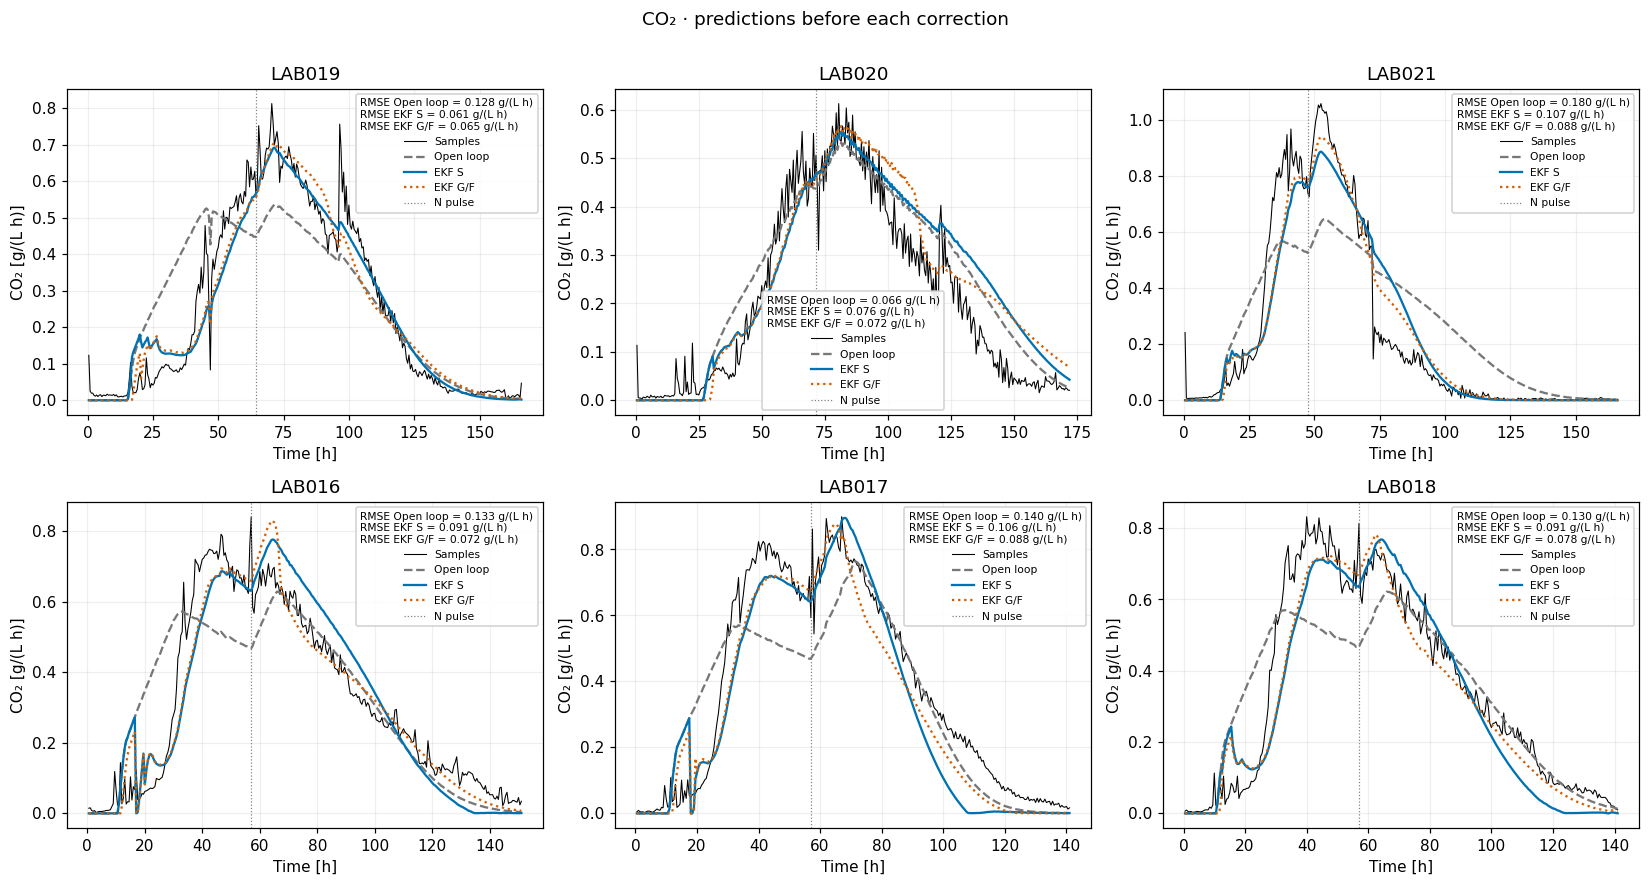

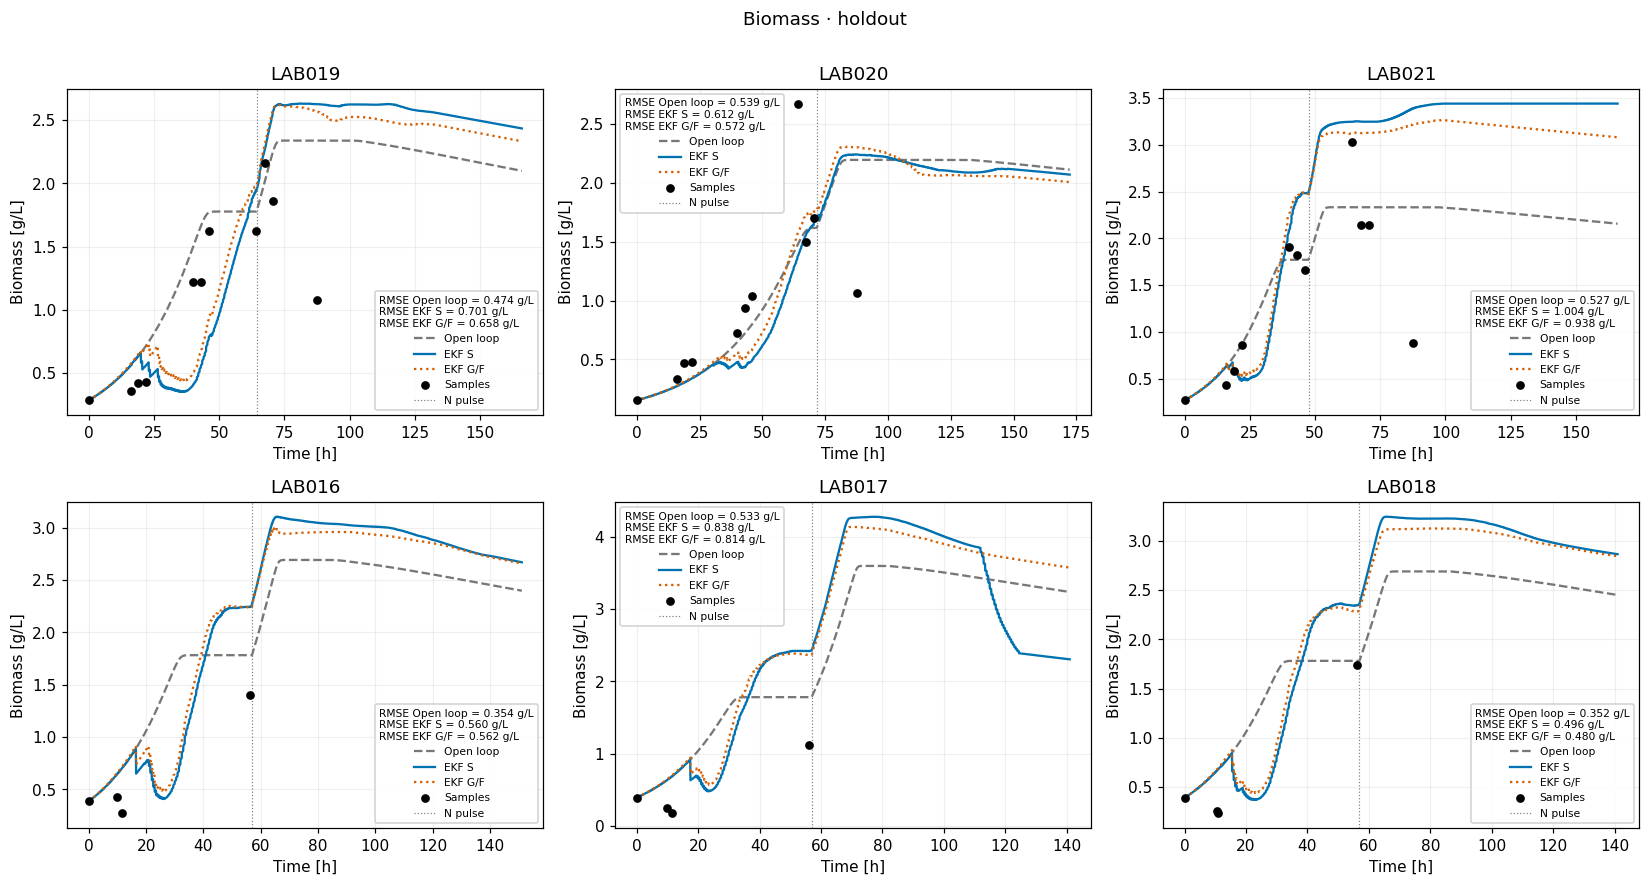

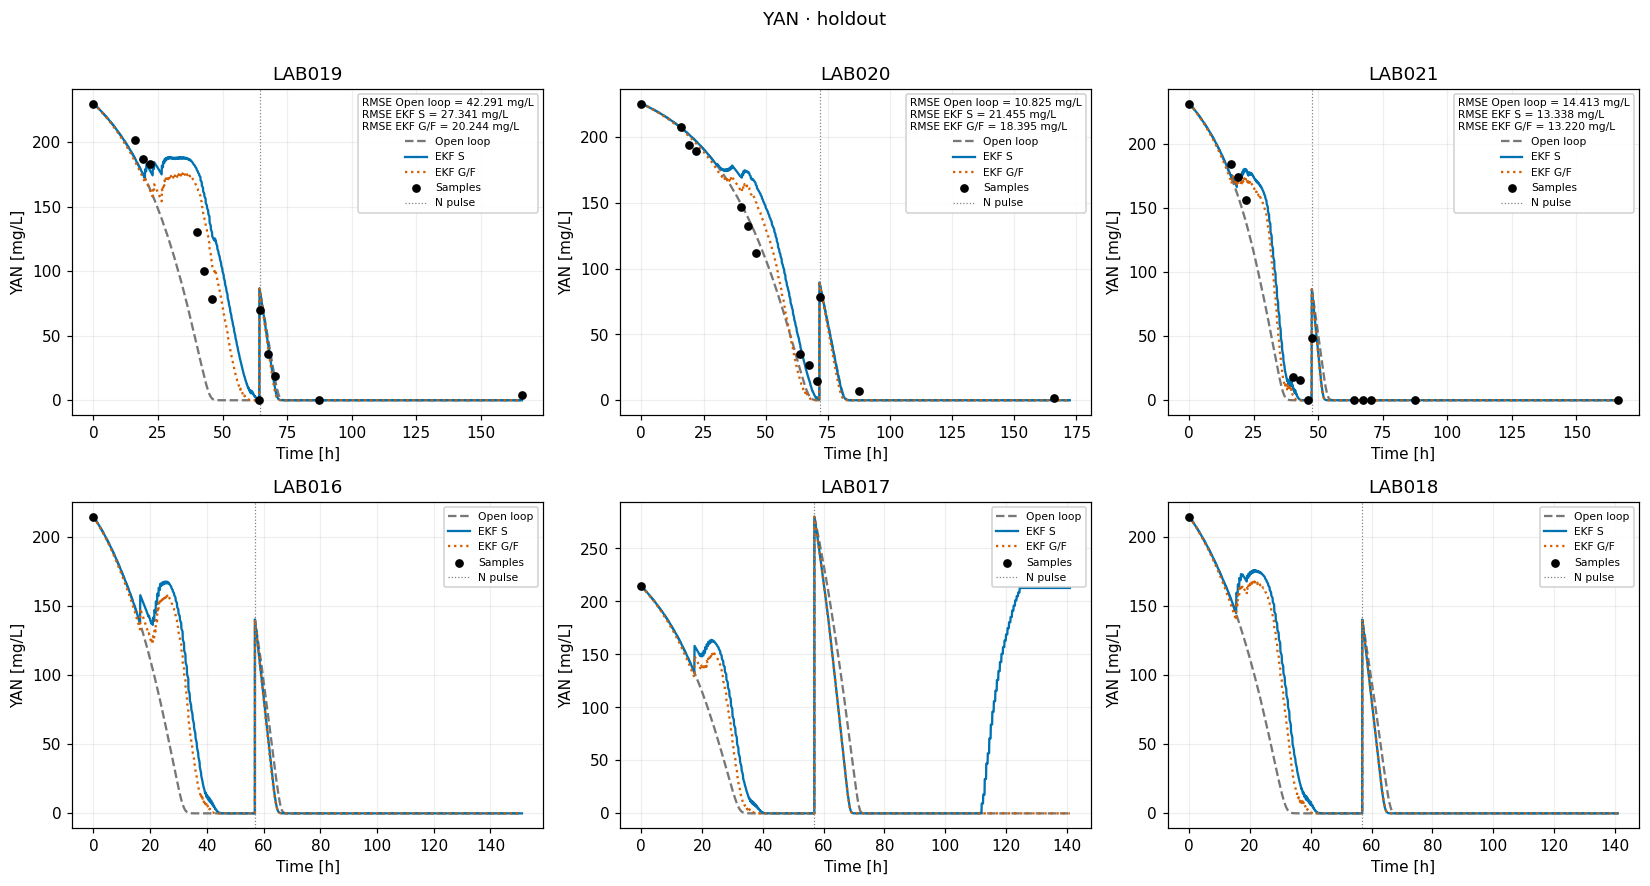

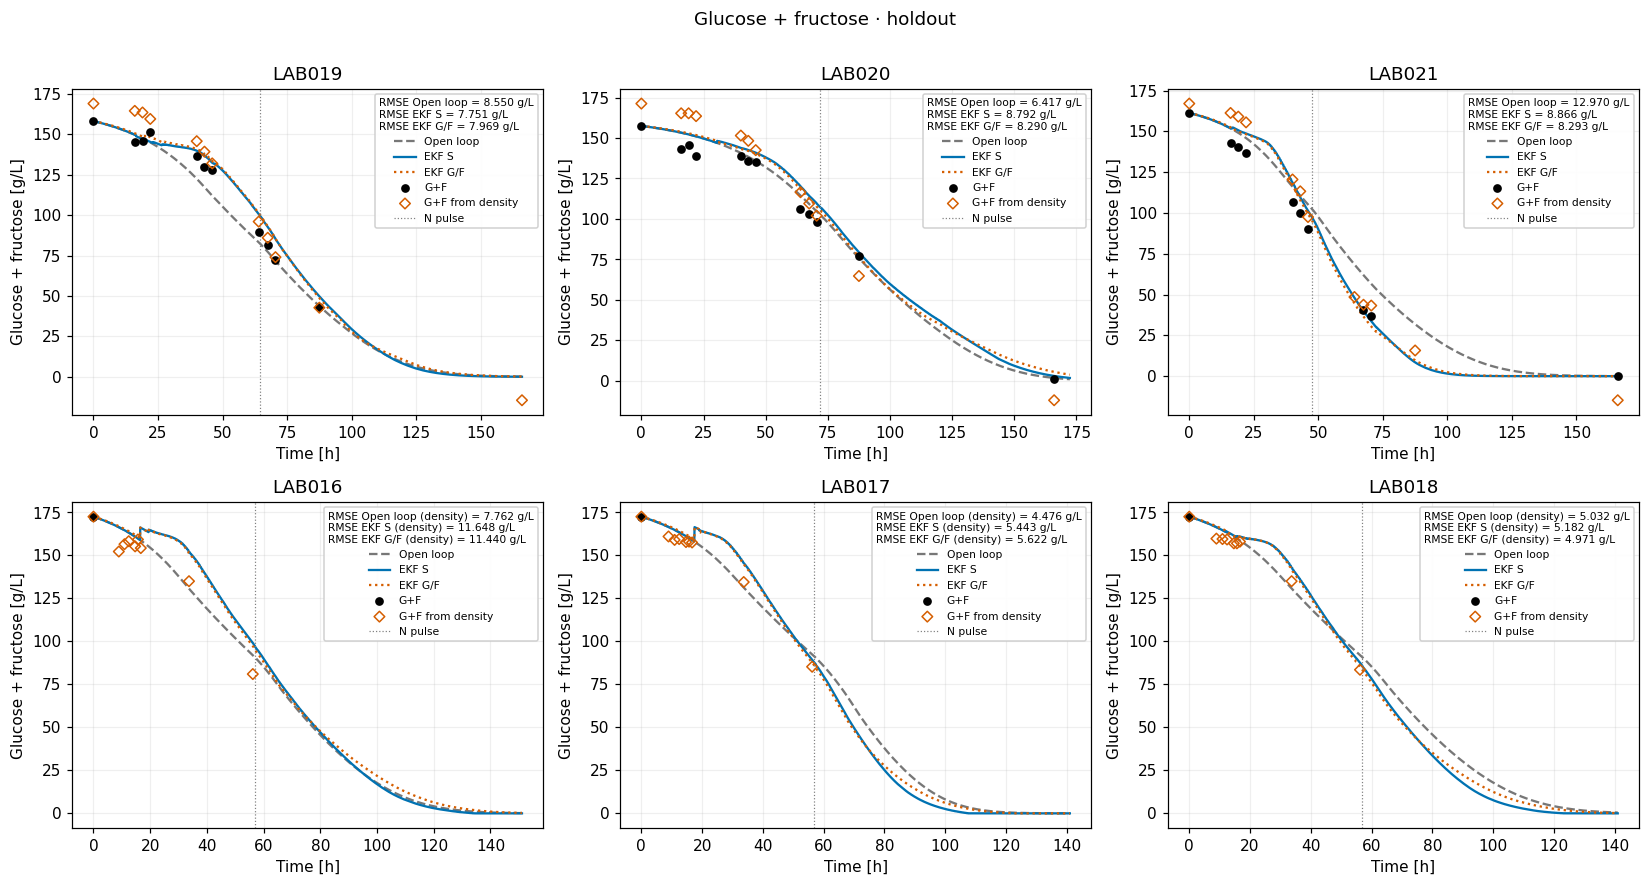

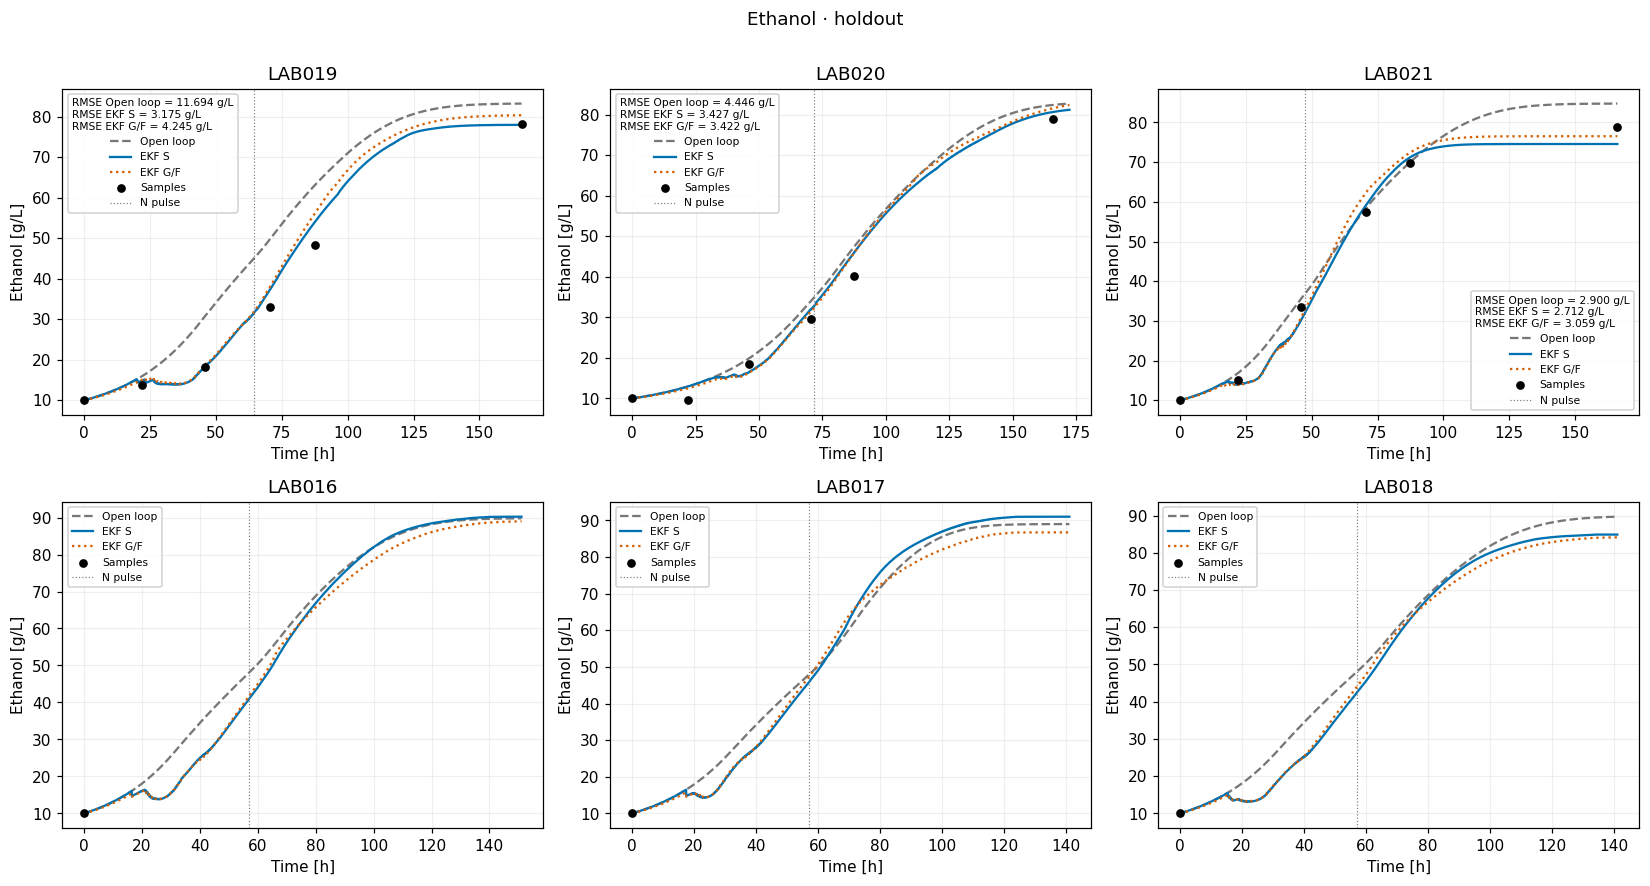

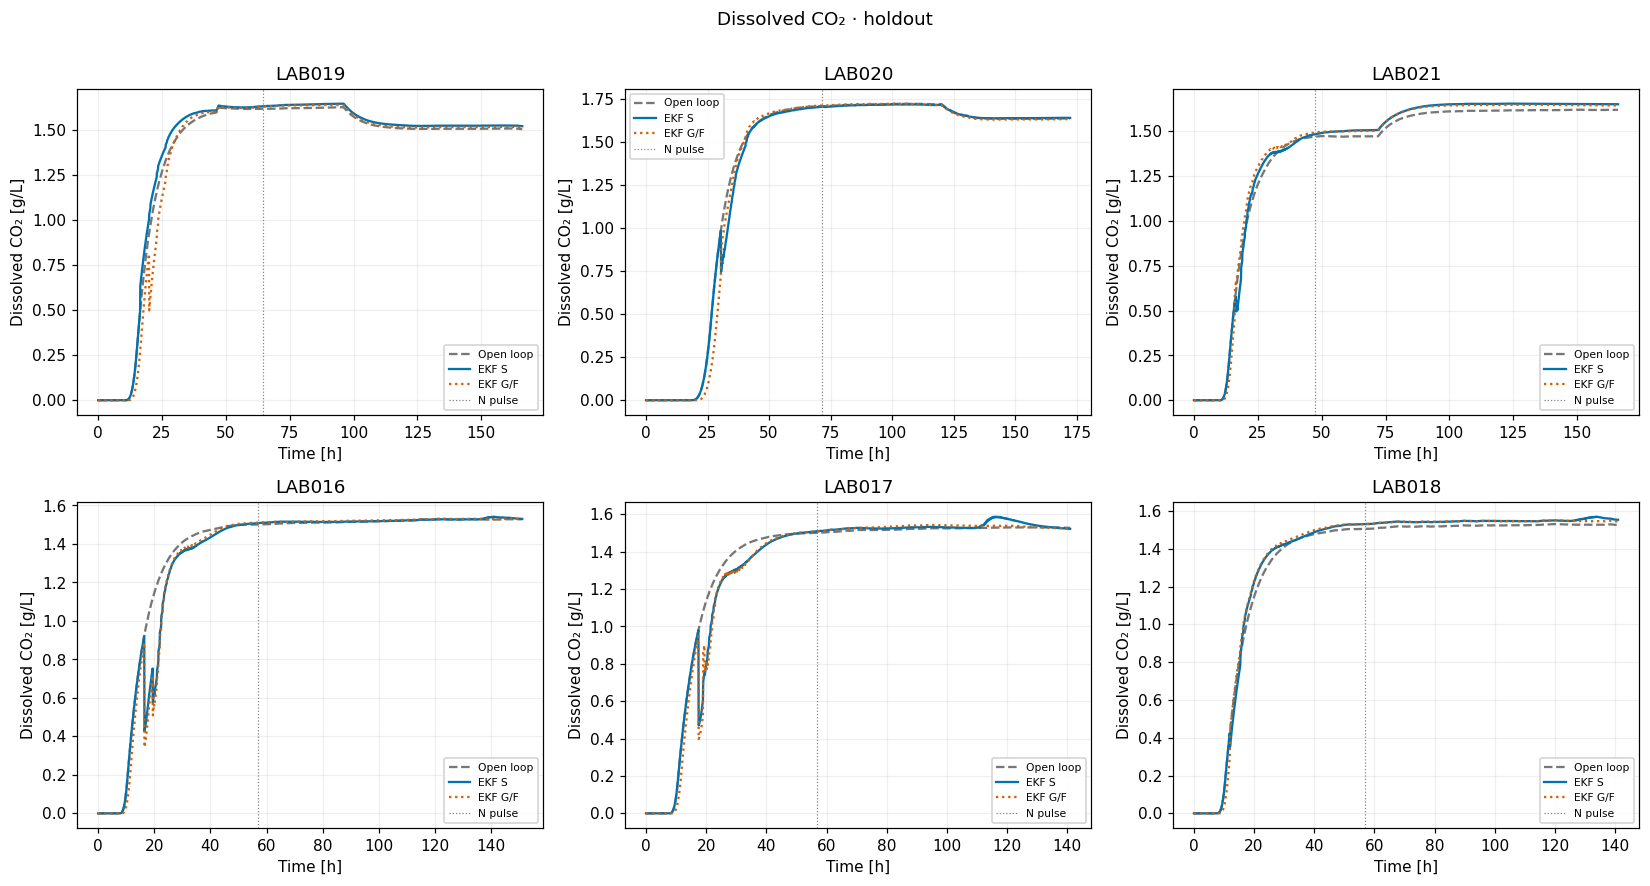

caso                      EKF_     EKF_GF     Libre_  forecast      free
LAB    variable n                                                       
LAB016 CO2      302        NaN   0.071952        NaN  0.091054  0.132839
       X        3     0.559788   0.561785   0.353829       NaN       NaN
LAB017 CO2      282        NaN   0.087554        NaN  0.106070  0.140310
       X        3     0.837943   0.814114   0.532896       NaN       NaN
LAB018 CO2      282        NaN   0.077929        NaN  0.090969  0.130355
       X        3     0.496240   0.479546   0.351761       NaN       NaN
LAB019 CO2      332        NaN   0.064583        NaN  0.060726  0.127579
       E        5     3.175459   4.245199  11.693976       NaN       NaN
       GF       10    7.750661   7.968872   8.550269       NaN       NaN
       N        12   27.341367  20.243967  42.290702       NaN       NaN
       X        10    0.700984   0.658065   0.473537       NaN       NaN
LAB020 CO2      344        NaN   0.072030        NaN  0.076039  0.065834
       E        5     3.426916   3.421604   4.446317       NaN       NaN
       GF       11    8.791970   8.289541   6.417172       NaN       NaN
       N        12   21.454631  18.395281  10.825362       NaN       NaN
       X        10    0.612134   0.572336   0.538572       NaN       NaN
LAB021 CO2      332        NaN   0.087668        NaN  0.107007  0.180492
       E        5     2.711589   3.059259   2.900261       NaN       NaN
       GF       9     8.865789   8.293438  12.969730       NaN       NaN
       N        12   13.337940  13.220344  14.413251       NaN       NaN
       X        10    1.004160   0.938329   0.527207       NaN       NaN

In [4]:
# Figure policy: English, local legends, compact layout, and RMSE in physical units.
KF_FIGURES={}
def kf_legend(ax,errors=None,unit='g/L'):
 handles,labels=ax.get_legend_handles_labels()
 unique=dict(zip(labels,handles))
 title='\n'.join(f"RMSE {name} = {value:.3f} {unit}" for name,value in (errors or {}).items())
 leg=ax.legend(unique.values(),unique.keys(),loc='best',fontsize=7,
               title=title or None,title_fontsize=7,framealpha=.90)
 assert len(leg.get_texts())==len(unique)

def kf_finish(fig,axs,title,key):
 fig.suptitle(title,y=.995)
 fig.tight_layout(pad=.7,h_pad=1.1,w_pad=.8,rect=(0,0,1,.975))
 assert not fig.legends
 KF_FIGURES[key]=fig
 plt.show()

def kf_observations(lab,state):
 # Return the original scoring arrays separately from the displayed samples.
 if lab in TRAIN:
  o=chemical_observations(v.chem,lab,state)
  tt=o.t_h.to_numpy();yy=o[CHEMICAL_COLUMNS[state]].to_numpy()
 elif state=='X':
  o=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l'])
  tt=o.t_h.to_numpy();yy=o.X_viable_g_l.to_numpy()
 else:
  o=pd.DataFrame();tt=np.array([]);yy=np.array([])
 mask=(tt>0)&(tt<=v.horizons[lab])
 if lab in TRAIN:
  if state=='GF' and 'GF_zero_substitution' in o:mask &= ~o.GF_zero_substitution.astype(str).str.lower().eq('true').to_numpy()
 return o,tt,yy,mask

def kf_draw_samples(ax,lab,state,frame,factor,tt,yy,mask):
 label='G+F' if state=='GF' else 'Samples'
 # Display and scoring have separate supports: NUT samples remain visible.
 shown=mask.copy();nut=np.zeros(len(tt),dtype=bool)
 if state=='N' and lab in TRAIN:
  observations_frame,_,_,_=kf_observations(lab,state)
  if 'is_NUT' in observations_frame:
   nut=observations_frame.is_NUT.astype(str).str.lower().eq('true').to_numpy()
   nut &= np.isfinite(yy)&(tt>0)&(tt<=v.horizons[lab])
   shown |= nut
 samples=ax.scatter(tt[shown],yy[shown]*factor,c='black',s=22,label=label,zorder=4)
 for tx,yx in zip(tt[nut],yy[nut]*factor):
  assert np.any(np.all(np.isclose(samples.get_offsets(),[tx,yx],rtol=0,atol=1e-9),axis=1))
 # Show the initial value actually used, with the same sample symbol and label.
 initial=float(frame['EKF_'+state].iloc[0])*factor
 point=ax.scatter([0.],[initial],c='black',s=22,label=label,zorder=4)
 assert np.allclose(point.get_offsets(),[[0.,initial]])
 density=None
 if state=='GF':
  d=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
  d=d.loc[d.t_h.between(0,v.horizons[lab])]
  ax.scatter(d.t_h,2.5*(d.density_g_l-1000),marker='D',facecolors='none',
             edgecolors='#D55E00',s=24,label='G+F from density',zorder=4)
  density=(d.t_h.to_numpy(),2.5*(d.density_g_l.to_numpy()-1000))
 return density

def kf_axes(ax,lab,ylabel):
 for t,d in batches[lab].pulses['N']:
  ax.axvline(t,c='gray',ls=':',lw=.8,label='N pulse')
 ax.set(title=lab,xlabel='Time [h]',ylabel=ylabel)
 ax.grid(alpha=.2)

CASES={'Open loop':RESULTS,'EKF S':RESULTS,'EKF G/F':RESULTS_GF}
COLORS={'Open loop':'#777777','EKF S':'#0072B2','EKF G/F':'#D55E00'}
STYLES={'Open loop':'--','EKF S':'-','EKF G/F':':'}

metrics_ekf=[];diagnostics=[]
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,lab in zip(axs.flat,LABS):
 sensor=RESULTS[lab]['sensor'];errors={}
 ax.plot(sensor.t_h,sensor.measured,c='black',lw=.7,label='Samples')
 for name,res in CASES.items():
  q=res[lab]['sensor'];column='free' if name=='Open loop' else 'forecast'
  assert np.allclose(q.measured,sensor.measured,equal_nan=True) and np.array_equal(q.assimilate,sensor.assimilate)
  ax.plot(q.t_h,q[column],color=COLORS[name],ls=STYLES[name],label=name.replace(' GF',' G/F'))
  mask=q.valid&np.isfinite(q.measured);error=q.loc[mask,column]-q.loc[mask,'measured']
  rmse=float(np.sqrt(np.mean(error**2)));errors[name.replace(' GF',' G/F')]=rmse
  case='EKF_GF' if name=='EKF G/F' else ('free' if name=='Open loop' else 'forecast')
  metrics_ekf.append(dict(LAB=lab,variable='CO2',caso=case,n=int(mask.sum()),RMSE=rmse))
  if False:
   d=res[lab]['diag'];diagnostics.append(dict(LAB=lab,caso=name,actualizaciones=len(d),NIS_medio=float(d.NIS.mean()),componentes_recortados=int(d.recortes.sum()),updates_con_recorte=int(d.recortes.gt(0).sum())))
 kf_axes(ax,lab,'CO₂ [g/(L h)]');kf_legend(ax,errors,'g/(L h)')
kf_finish(fig,axs,'CO₂ · predictions before each correction','CO2')
for state,title,factor in [('X','Biomass',1),('N','YAN',1000),('GF','Glucose + fructose',1),('E','Ethanol',1),('Cd','Dissolved CO₂',1)]:
 fig,axs=plt.subplots(2,3,figsize=(15,8))
 for ax,lab in zip(axs.flat,LABS):
  selected={k:v for k,v in CASES.items() if state not in ['G','F'] or k.endswith(('GF','G/F')) or k=='Open loop'}
  errors={}
  for name,res in selected.items():
   f=res[lab]['frame'];prefix='Libre_' if name=='Open loop' else 'EKF_'
   ax.plot(f.t_h,f[prefix+state]*factor,color=COLORS[name],ls=STYLES[name],label=name.replace(' GF',' G/F'))
  if state!='Cd':
   o,tt,yy,mask=kf_observations(lab,state)
   density=kf_draw_samples(ax,lab,state,next(iter(selected.values()))[lab]['frame'],factor,tt,yy,mask)
   for name,res in selected.items():
    f=res[lab]['frame'];prefix='Libre_' if name=='Open loop' else 'EKF_'
    error=(np.interp(tt[mask],f.t_h,f[prefix+state])-yy[mask])*factor
    if len(error):
     rmse=float(np.sqrt(np.mean(error**2)));errors[name.replace(' GF',' G/F')]=rmse
     case='EKF_GF' if name=='EKF G/F' else ('Libre_' if name=='Open loop' else 'EKF_')
     metrics_ekf.append(dict(LAB=lab,variable=state,caso=case,n=len(error),RMSE=rmse))
    elif density is not None:
     dt,dy=density;dm=dt>0
     if dm.any():errors[name.replace(' GF',' G/F')+' (density)']=float(np.sqrt(np.mean((np.interp(dt[dm],f.t_h,f[prefix+state])-dy[dm])**2)))
  unit='mg/L' if state=='N' else 'g/L'
  kf_axes(ax,lab,title+' ['+unit+']');kf_legend(ax,errors,unit)
 kf_finish(fig,axs,title+' · holdout','X' if state=='X' else state)
metrics_ekf=pd.DataFrame(metrics_ekf)
print('METRICS_VARIABLE_JSON',metrics_ekf.to_json(orient='records'))
display(metrics_ekf.pivot(index=['LAB','variable','n'],columns='caso',values='RMSE'));print('METRICS_JSON',metrics_ekf.to_json(orient='records'))
for lab in LABS:
 for label,res in [('G/F',RESULTS_GF),('S',RESULTS)]:
  d=res[lab]['diag'];print(lab,label,'NIS medio',d.NIS.mean(),'recortes',int(d.recortes.sum()),'actualizaciones con recorte',int(d.recortes.gt(0).sum()))
assert theta==BASE_THETA and (KLA,GAIN)==GAS_PARAMETERS['S'] and BASE_GAS==GAS_PARAMETERS['GF']
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in hashes.items())
print('Parámetros y datos intactos. Ninguna muestra química asimilada. Incertidumbres exploratorias, no validadas.')

def terms_s(t,y,p,b):
 x,n,s,e=np.maximum(y,0);tk=kin.temperature_at(b,t)+273.15;R=kin.FIXED_CONSTANTS['R']
 ak=np.exp(46055*(tk-293.15)/(293.15*R*tk))
 mu=p['mu0']*np.exp(59453*(tk-300)/(300*R*tk))*n/(n+theta['Kn0']*ak+1e-8) if s>0 else 0.
 beta=p['betaS0']*np.exp(11000*(tk-296.15)/(296.15*R*tk))*s/(s+p['Ks0']*ak+1e-8)*(p['Kie0']*(ak+1e-8)/(e+p['Kie0']*(ak+1e-8)))
 td=-.0001*e**3+.0049*e**2-.1279*e+315.89
 kd=theta['Kd0']*np.exp(.0415*e+130000*(tk-305.65)/(305.65*R*tk)) if tk>=td else 0.
 maint=theta['m0']*np.exp(37681*(tk-293.3)/(293.3*R*tk))*s/(s+kin.MAINTENANCE_SUGAR_CUTOFF_KG_M3)
 return mu,beta,kd,maint


for T in [16.,20.,24.]:
 b=replace(batches['LAB019'],time=np.array([0.,1.]),temperature_c=np.array([T,T]));y=np.array([1.,.05,90.,30.]);mu,be,kd,m=terms_s(0,y,PS,b)
 expected=np.array([(mu-kd)*y[0],-mu*y[0]/PS['Yxn'],-(mu/YXS+be/PS['Yes']+m)*y[0],be*y[0]])
 actual=rates_ekf(np.array([np.r_[y,.2,0.]]),0,T,160)[0,:4];assert np.max(abs(actual-expected))<1e-8
ztest=np.array([1.,.05,90.,30.,.2,0.])/SCALE_EKF
x1=transition(ztest,24,24+1/12,lambda t:20.,160.)[0];x2=transition(ztest,24,24+1/12,lambda t:20.,160.,step=1/120)[0]
assert np.max(abs((x1-x2)*SCALE_EKF))<1e-4
assert PS['Kie0']==THETA_GF['Kie0'] and theta==THETA_GF
print('RHS contrastado con escalar del17, integración refinada, PSD y mismas ventanas/actualizaciones que02 comprobados. Ninguna muestra offline asimilada.')


## Results and limitations

The new EKF runs agree exactly between the standalone notebooks and the combined comparison (states, forecasts, diagnostics and stored variances). All four estimators use identical measurements, timestamps and correction masks. Covariance PSD, RHS consistency, gas balance, transition Jacobians, time-step refinement and sigma-point moments were checked. Original notebooks and audit files remain unchanged.

**LAB017, EKF S:** estimated YAN rebounds late, reaching 212.7445 mg/L at 124.5 h without a new nutrient pulse. All 31 positive increments after 100 h coincide with measurement-correction times. This is an estimator correction effect, not nitrogen production in the biological RHS (which consumes N between pulses). No late LAB017 YAN measurements are available to validate this rebound. UKF S remains below 0.141 mg/L after 100 h. Good CO2 tracking therefore does not establish reliable chemical-state estimates. The inherited covariance/projection assumptions are retained; no parameter or matrix was retuned to suppress this result.


## Evaluation including nutrition samples

YAN RMSE includes all 12 post-initial analytical samples in each of LAB019–021, including NUT. Units: mg/L. Offline samples remain evaluation data; no new filter update or fit was introduced. CO2 and other-state RMSE are unchanged.

| Case | LAB019 | LAB020 | LAB021 | Mean per LAB |
|---|---:|---:|---:|---:|
| Open loop | 42.2907 | 10.8254 | 14.4133 | 22.5098 |
| EKF S | 27.3414 | 21.4546 | 13.3379 | 20.7113 |
| EKF G/F | 20.2440 | 18.3953 | 13.2203 | 17.2865 |
